# EDA — Drug Interactions Dataset

**Dataset:** `db_drug_interactions.csv`

This notebook performs a complete exploratory data analysis (EDA) for a drug–drug interaction dataset.

### EDA goals
1. Understand the structure and schema.
2. Check data quality: missing values, blanks, duplicates, formatting issues.
3. Analyze the drug columns and interaction-pair structure.
4. Analyze the interaction-description text.
5. Detect duplicated/reversed drug pairs and other potential data-quality issues.
6. Create visualizations that can be used in a professional project report.
7. Finish with findings, implications, and recommendations for ML preprocessing.

> **Important:** This dataset contains drug pairs and interaction descriptions. It does **not** contain an explicit `interaction = 0/1` target column, so EDA can describe the interaction records but cannot by itself prove that a non-listed pair has no interaction.


## 1. Imports and display settings

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 120)

# Load the dataset
df = pd.read_csv("db_drug_interactions.csv")

print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]:,}")
df.head()


Rows: 191,541
Columns: 3


,Drug 1,Drug 2,Interaction Description
0,Trioxsalen,Verteporfin,Trioxsalen may increase the photosensitizing activities of Verteporfin.
1,Aminolevulinic acid,Verteporfin,Aminolevulinic acid may increase the photosensitizing activities of Verteporfin.
2,Titanium dioxide,Verteporfin,Titanium dioxide may increase the photosensitizing activities of Verteporfin.
3,Tiaprofenic acid,Verteporfin,Tiaprofenic acid may increase the photosensitizing activities of Verteporfin.
4,Cyamemazine,Verteporfin,Cyamemazine may increase the photosensitizing activities of Verteporfin.


## 2. First look: shape, columns, data types, and sample records

In [15]:
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.to_frame("dtype"))

print("\nRandom sample:")
display(df.sample(10, random_state=6))


Shape: (191541, 3)

Columns:
['Drug 1', 'Drug 2', 'Interaction Description']

Data types:


,dtype
Drug 1,str
Drug 2,str
Interaction Description,str



Random sample:


,Drug 1,Drug 2,Interaction Description
74651,Fenoldopam,Ropinirole,The risk or severity of adverse effects can be increased when Fenoldopam is combined with Ropinirole.
93967,Pimecrolimus,Chlorambucil,The risk or severity of adverse effects can be increased when Pimecrolimus is combined with Chlorambucil.
95171,Tolcapone,Trandolapril,The risk or severity of adverse effects can be increased when Tolcapone is combined with Trandolapril.
51380,Prednicarbate,Stiripentol,The serum concentration of Stiripentol can be increased when it is combined with Prednicarbate.
19718,Calcium gluconate,Bendroflumethiazide,Calcium gluconate may decrease the excretion rate of Bendroflumethiazide which could result in a higher serum level.
139193,Alprazolam,Ezogabine,The risk or severity of adverse effects can be increased when Alprazolam is combined with Ezogabine.
94098,Methylphenobarbital,Mecamylamine,Methylphenobarbital may increase the hypotensive activities of Mecamylamine.
78545,Repaglinide,Abiraterone,The serum concentration of Abiraterone can be increased when it is combined with Repaglinide.
103388,Triamterene,Quetiapine,The risk or severity of adverse effects can be increased when Triamterene is combined with Quetiapine.
49219,Nitrazepam,Telithromycin,The metabolism of Telithromycin can be decreased when combined with Nitrazepam.


## 3. Data-quality audit
We check missing values, blank strings, whitespace, duplicated rows, and duplicated drug names caused only by capitalization/spacing.

In [16]:
quality = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_count": df.isna().sum(),
    "missing_pct": df.isna().mean().mul(100).round(3),
    "unique_values": df.nunique(dropna=False),
    "blank_or_whitespace": [
        df[c].fillna("").astype(str).str.strip().eq("").sum()
        for c in df.columns
    ],
})

display(quality)

print("Exact duplicated rows:", df.duplicated().sum())

for c in ["Drug 1", "Drug 2"]:
    normalized = df[c].astype(str).str.strip().str.casefold()
    print(
        f"{c}: original unique={df[c].nunique():,}, "
        f"normalized unique={normalized.nunique():,}"
    )
    print(f"{c}: rows changed by strip={((df[c].astype(str)) != df[c].astype(str).str.strip()).sum()}")


,dtype,missing_count,missing_pct,unique_values,blank_or_whitespace
Drug 1,str,0,0.0,1634,0
Drug 2,str,0,0.0,1606,0
Interaction Description,str,0,0.0,191541,0


Exact duplicated rows: 0
Drug 1: original unique=1,634, normalized unique=1,634
Drug 1: rows changed by strip=0
Drug 2: original unique=1,606, normalized unique=1,606
Drug 2: rows changed by strip=0


## 4. Basic descriptive statistics for text columns

In [17]:
for c in df.columns:
    s = df[c].dropna().astype(str)
    print(f"\n### {c}")
    print("Unique:", s.nunique())
    print("Minimum length:", s.str.len().min())
    print("Maximum length:", s.str.len().max())
    print("Mean length:", round(s.str.len().mean(), 2))
    print("Median length:", s.str.len().median())



### Drug 1
Unique: 1634
Minimum length: 4
Maximum length: 31
Mean length: 11.17
Median length: 11.0

### Drug 2
Unique: 1606
Minimum length: 4
Maximum length: 31
Mean length: 11.26
Median length: 11.0

### Interaction Description
Unique: 191541
Minimum length: 58
Maximum length: 195
Mean length: 89.85
Median length: 92.0


## 5. Drug universe and column overlap

In [18]:
drug1 = set(df["Drug 1"])
drug2 = set(df["Drug 2"])
all_drugs = drug1 | drug2
both_columns = drug1 & drug2

print("Unique drugs in Drug 1:", len(drug1))
print("Unique drugs in Drug 2:", len(drug2))
print("Unique drugs overall:", len(all_drugs))
print("Drugs appearing in both columns:", len(both_columns))
print("Only in Drug 1:", len(drug1 - drug2))
print("Only in Drug 2:", len(drug2 - drug1))

print("\nExamples only in Drug 1:")
display(pd.DataFrame(sorted(drug1 - drug2)[:20], columns=["Drug"]))

print("Examples only in Drug 2:")
display(pd.DataFrame(sorted(drug2 - drug1)[:20], columns=["Drug"]))


Unique drugs in Drug 1: 1634
Unique drugs in Drug 2: 1606
Unique drugs overall: 1701
Drugs appearing in both columns: 1539
Only in Drug 1: 95
Only in Drug 2: 67

Examples only in Drug 1:


,Drug
0,Activated charcoal
1,Adefovir dipivoxil
2,Aluminum oxide
3,Aluminum sulfate
4,Aminocaproic acid
5,Aprindine
6,Avibactam
7,Aztreonam
8,Bacitracin
9,Benzophenone


Examples only in Drug 2:


,Drug
0,Acetohydroxamic acid
1,Acipimox
2,Adenosine
3,Alfacalcidol
4,Benzoctamine
5,Bethanechol
6,Bisacodyl
7,Cannabidiol
8,Canrenoic acid
9,Captodiame


## 6. Drug frequency analysis
Each interaction row contains two drugs. We count how often each drug appears across both columns.

,interaction_appearances
Phenobarbital,920
Primidone,896
Phenytoin,895
Fosphenytoin,877
Carbamazepine,868
Venlafaxine,860
Pentobarbital,845
Fluvoxamine,845
Amiodarone,844
Nefazodone,815


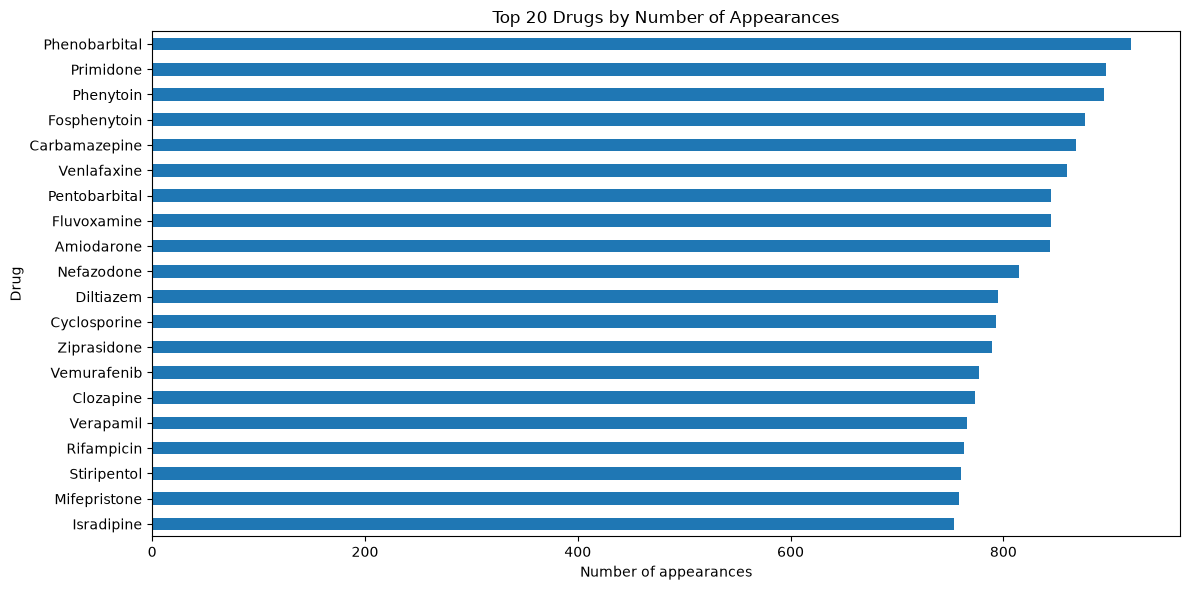

In [19]:
drug_frequency = pd.concat(
    [df["Drug 1"], df["Drug 2"]],
    ignore_index=True
).value_counts()

display(drug_frequency.head(20).to_frame("interaction_appearances"))

plt.figure(figsize=(12, 6))
drug_frequency.head(20).sort_values().plot(kind="barh")
plt.title("Top 20 Drugs by Number of Appearances")
plt.xlabel("Number of appearances")
plt.ylabel("Drug")
plt.tight_layout()
plt.show()


## 7. Drug 1 vs Drug 2 distribution

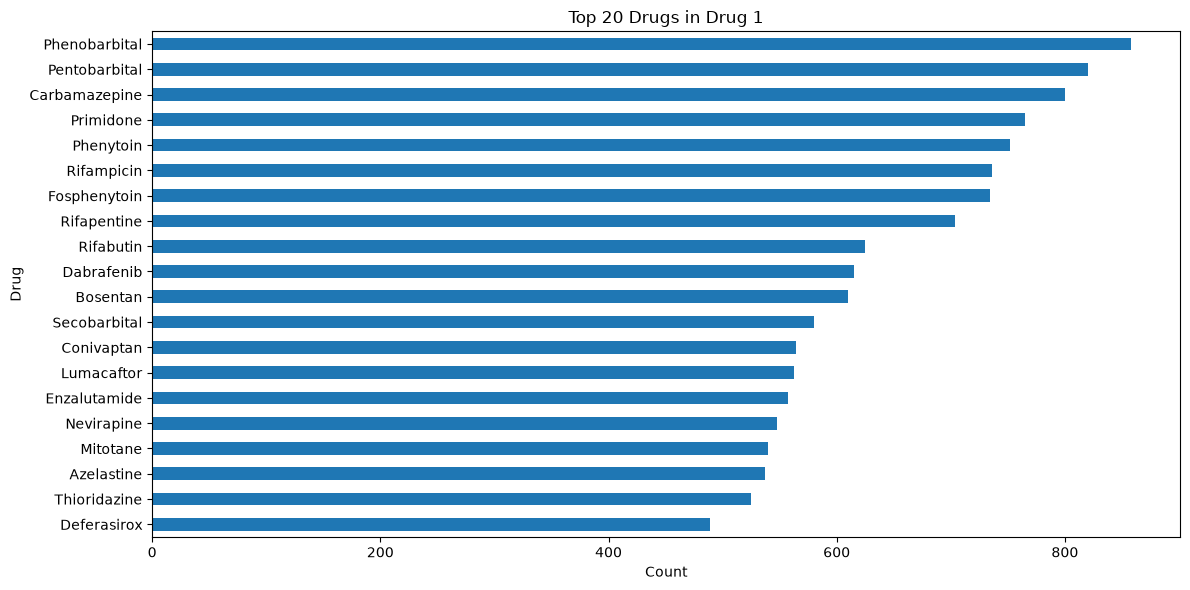

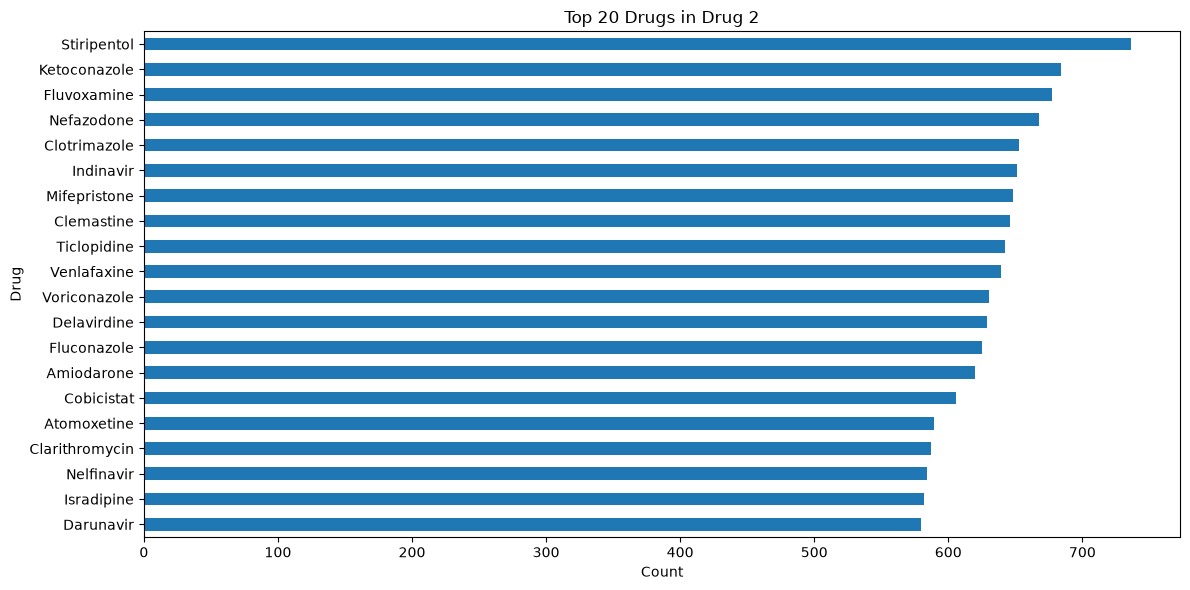

In [20]:
drug1_counts = df["Drug 1"].value_counts()
drug2_counts = df["Drug 2"].value_counts()

fig = plt.figure(figsize=(12, 6))
drug1_counts.head(20).sort_values().plot(kind="barh")
plt.title("Top 20 Drugs in Drug 1")
plt.xlabel("Count")
plt.ylabel("Drug")
plt.tight_layout()
plt.show()

fig = plt.figure(figsize=(12, 6))
drug2_counts.head(20).sort_values().plot(kind="barh")
plt.title("Top 20 Drugs in Drug 2")
plt.xlabel("Count")
plt.ylabel("Drug")
plt.tight_layout()
plt.show()


## 8. Interaction-pair uniqueness and duplicates
An exact row can be unique even when the same drug pair appears more than once with different descriptions. Therefore we inspect pair-level duplicates separately.

In [21]:
directed_pair_counts = df.groupby(["Drug 1", "Drug 2"]).size().sort_values(ascending=False)

print("Rows:", len(df))
print("Unique directed pairs:", len(directed_pair_counts))
print("Directed pair duplicate groups:", (directed_pair_counts > 1).sum())
print("Rows belonging to directed duplicate groups:", directed_pair_counts[directed_pair_counts > 1].sum())

print("\nTop repeated directed pairs:")
display(directed_pair_counts[directed_pair_counts > 1].head(20).to_frame("records"))

directed_dups = df.merge(
    directed_pair_counts.rename("pair_count").reset_index(),
    on=["Drug 1", "Drug 2"]
)
directed_dups = directed_dups[directed_dups["pair_count"] > 1]

display(
    directed_dups.sort_values(["Drug 1", "Drug 2"])
    [["Drug 1", "Drug 2", "Interaction Description", "pair_count"]]
    .head(20)
)


Rows: 191541
Unique directed pairs: 191252
Directed pair duplicate groups: 289
Rows belonging to directed duplicate groups: 578

Top repeated directed pairs:


records
Drug 1        Drug 2                  
Doxorubicin   Crizotinib             2
Amodiaquine   Irbesartan             2
Doxorubicin   Indinavir              2
              Indomethacin           2
              Isavuconazonium        2
              Isoniazid              2
Amodiaquine   Lapatinib              2
Doxorubicin   Isradipine             2
              Darifenacin            2
              Itraconazole           2
              Posaconazole           2
              Vincristine            2
Amodiaquine   Losartan               2
Doxorubicin   Delavirdine            2
              Desipramine            2
Fosphenytoin  Ranolazine             2
Carbamazepine Moclobemide            2
Doxorubicin   Ketoconazole           2
              Voriconazole           2
Chloroquine   Mifepristone           2

,Drug 1,Drug 2,Interaction Description,pair_count
77615,Amodiaquine,Celecoxib,The metabolism of Celecoxib can be decreased when combined with Amodiaquine.,2
77616,Amodiaquine,Celecoxib,The serum concentration of Celecoxib can be increased when it is combined with Amodiaquine.,2
26455,Amodiaquine,Clotrimazole,The metabolism of Clotrimazole can be decreased when combined with Amodiaquine.,2
26456,Amodiaquine,Clotrimazole,The serum concentration of Clotrimazole can be increased when it is combined with Amodiaquine.,2
85213,Amodiaquine,Crisaborole,The metabolism of Crisaborole can be decreased when combined with Amodiaquine.,2
85214,Amodiaquine,Crisaborole,The serum concentration of Crisaborole can be increased when it is combined with Amodiaquine.,2
69059,Amodiaquine,Efavirenz,The serum concentration of Efavirenz can be increased when it is combined with Amodiaquine.,2
69060,Amodiaquine,Efavirenz,Amodiaquine may increase the hepatotoxic activities of Efavirenz.,2
63584,Amodiaquine,Felodipine,The metabolism of Felodipine can be decreased when combined with Amodiaquine.,2
63585,Amodiaquine,Felodipine,The serum concentration of Felodipine can be increased when it is combined with Amodiaquine.,2


## 9. Reversed pairs
For some interaction datasets, `(A, B)` and `(B, A)` represent the same unordered drug pair. We therefore check whether reverse records exist.

In [22]:
pair_set = set(map(tuple, df[["Drug 1", "Drug 2"]].itertuples(index=False, name=None)))

reverse_rows = sum(
    (b, a) in pair_set
    for a, b in df[["Drug 1", "Drug 2"]].itertuples(index=False, name=None)
)

print("Rows whose reversed pair also exists:", reverse_rows)

# Canonical unordered pair
canonical = pd.DataFrame({
    "Drug_A": np.minimum(df["Drug 1"].values, df["Drug 2"].values),
    "Drug_B": np.maximum(df["Drug 1"].values, df["Drug 2"].values)
})

unordered_counts = canonical.value_counts()

print("Unique unordered pairs:", len(unordered_counts))
print("Unordered duplicate groups:", (unordered_counts > 1).sum())
print("Rows in unordered duplicate groups:", unordered_counts[unordered_counts > 1].sum())

display(unordered_counts[unordered_counts > 1].head(20).to_frame("records"))


Rows whose reversed pair also exists: 234
Unique unordered pairs: 191135
Unordered duplicate groups: 406
Rows in unordered duplicate groups: 812


records
Drug_A          Drug_B                  
Digoxin         Doxorubicin            2
                Vincristine            2
                Ledipasvir             2
Amodiaquine     Teriflunomide          2
Doxorubicin     Haloperidol            2
Haloperidol     Metoclopramide         2
Dexamethasone   Ledipasvir             2
Pantoprazole    Risedronic acid        2
Dexlansoprazole Risedronic acid        2
Lansoprazole    Risedronic acid        2
Esomeprazole    Risedronic acid        2
Rabeprazole     Risedronic acid        2
Omeprazole      Risedronic acid        2
Cimetidine      Risedronic acid        2
Methylphenidate Pargyline              2
Doxorubicin     Sulfisoxazole          2
                Erythromycin           2
Cyclosporine    Doxorubicin            2
                Vincristine            2
                Ledipasvir             2

## 10. Self-interactions

In [23]:
self_interactions = (df["Drug 1"] == df["Drug 2"]).sum()
print("Self-interaction rows:", self_interactions)


Self-interaction rows: 0


## 11. Pair coverage / sparsity
This is useful for understanding how sparse the drug-interaction graph is. The calculation assumes that a pair is unordered for the coverage estimate.

In [24]:
n_drugs = len(all_drugs)
possible_unordered = n_drugs * (n_drugs - 1) // 2
observed_unordered = len(unordered_counts)

print(f"Possible unordered pairs (no self-pairs): {possible_unordered:,}")
print(f"Observed unique unordered pairs: {observed_unordered:,}")
print(f"Approximate observed coverage: {observed_unordered / possible_unordered:.2%}")


Possible unordered pairs (no self-pairs): 1,445,850
Observed unique unordered pairs: 191,135
Approximate observed coverage: 13.22%


## 12. Interaction-description length analysis

,description_length,description_word_count
count,191541.00,191541.00
mean,89.85,12.99
std,15.90,3.20
min,58.00,8.00
25%,76.00,11.00
50%,92.00,14.00
75%,102.00,16.00
max,195.00,29.00


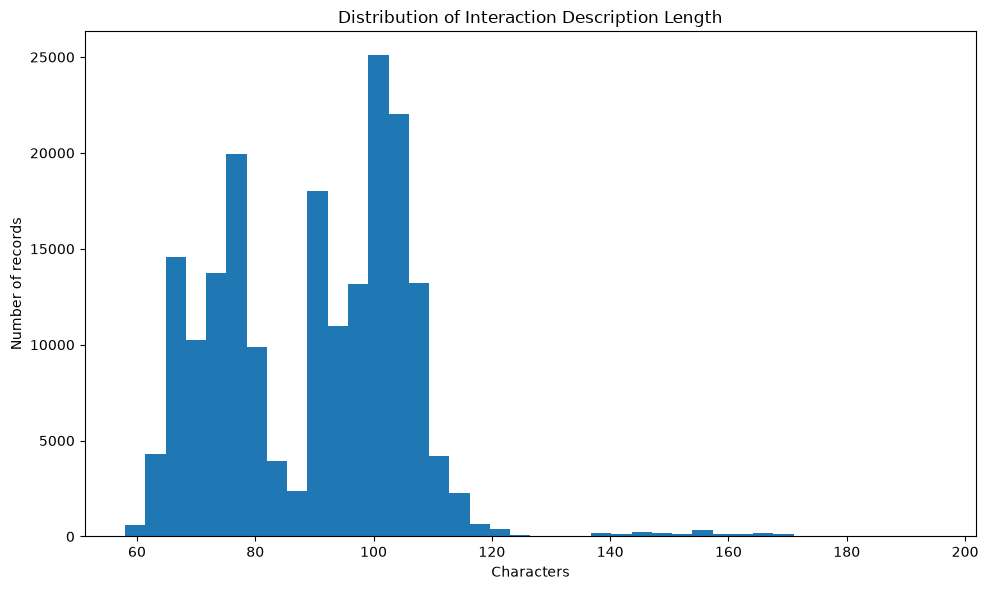

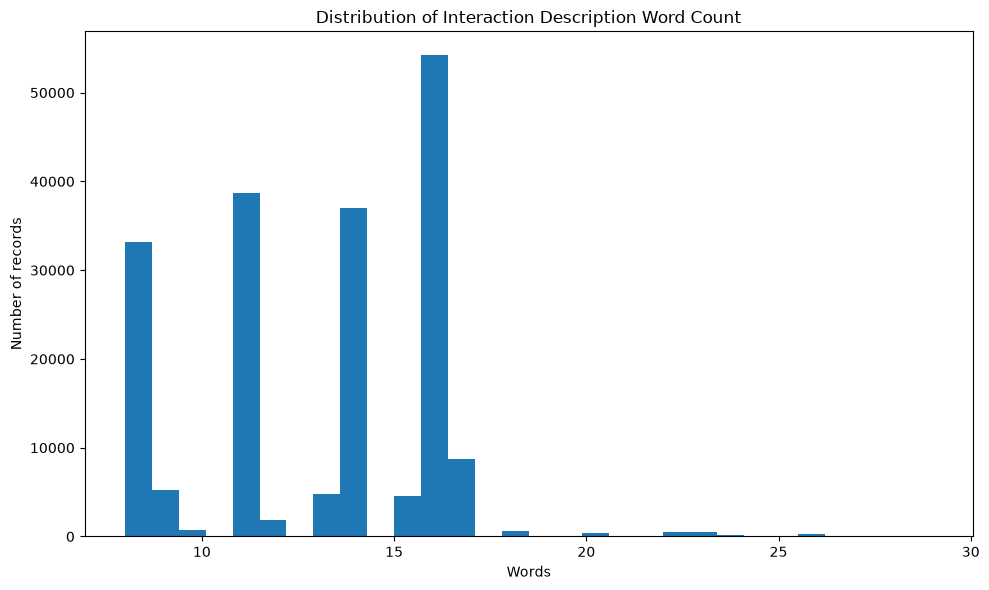

In [25]:
df["description_length"] = df["Interaction Description"].str.len()
df["description_word_count"] = df["Interaction Description"].str.split().str.len()

display(
    df[["description_length", "description_word_count"]]
    .describe()
    .round(2)
)

plt.figure(figsize=(10, 6))
plt.hist(df["description_length"], bins=40)
plt.title("Distribution of Interaction Description Length")
plt.xlabel("Characters")
plt.ylabel("Number of records")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 6))
plt.hist(df["description_word_count"], bins=30)
plt.title("Distribution of Interaction Description Word Count")
plt.xlabel("Words")
plt.ylabel("Number of records")
plt.tight_layout()
plt.show()


## 13. Interaction-description pattern analysis
Keyword counts are exploratory only. They are not a medically validated severity classification.

,records
increase,131706
decrease,61691
adverse effects,60804
metabolism,40161
serum concentration,34994
therapeutic efficacy,8024
toxicity,2074
excretion,1856
sedation,1569
absorption,1020


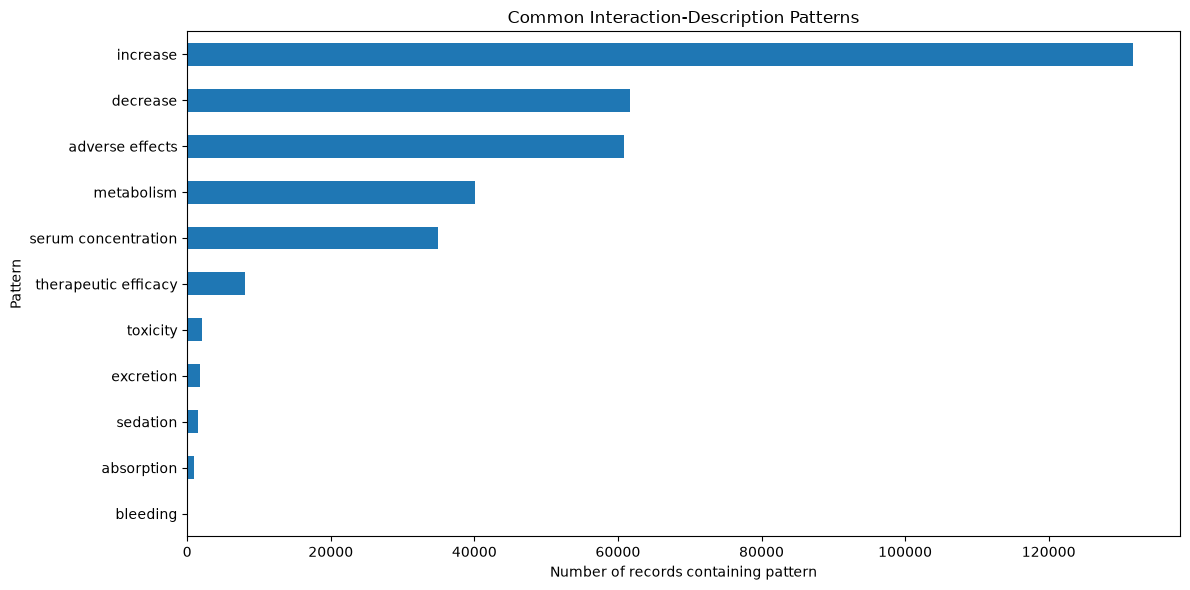

In [26]:
desc = df["Interaction Description"].str.lower()

patterns = {
    "increase": r"\bincrease|increased|increasing|elevat|higher|enhanc",
    "decrease": r"\bdecrease|decreased|decreasing|reduc|lower|diminish",
    "serum concentration": r"serum concentration|plasma concentration|concentration of",
    "metabolism": r"metabolism|metabol",
    "toxicity": r"toxic|hepatotoxic|nephrotoxic|cardiotoxic",
    "bleeding": r"bleed|hemorrhag",
    "sedation": r"sedat",
    "adverse effects": r"adverse effects|adverse reactions",
    "therapeutic efficacy": r"therapeutic efficacy",
    "absorption": r"absorption|absorbed",
    "excretion": r"excretion|renal clearance|clearance",
}

keyword_counts = pd.Series({
    label: desc.str.contains(pattern, regex=True).sum()
    for label, pattern in patterns.items()
}).sort_values(ascending=False)

display(keyword_counts.to_frame("records"))

plt.figure(figsize=(12, 6))
keyword_counts.sort_values().plot(kind="barh")
plt.title("Common Interaction-Description Patterns")
plt.xlabel("Number of records containing pattern")
plt.ylabel("Pattern")
plt.tight_layout()
plt.show()


## 14. Common description templates
This helps reveal whether multiple records follow the same linguistic structure.

,records
Interaction Description,
The risk or severity ...,61370
The metabolism of ...,39313
Drug may increase ...,38855
The serum concentration of ...,34019
Drug may decrease ...,8373
The therapeutic efficacy ...,8024
Other,1587


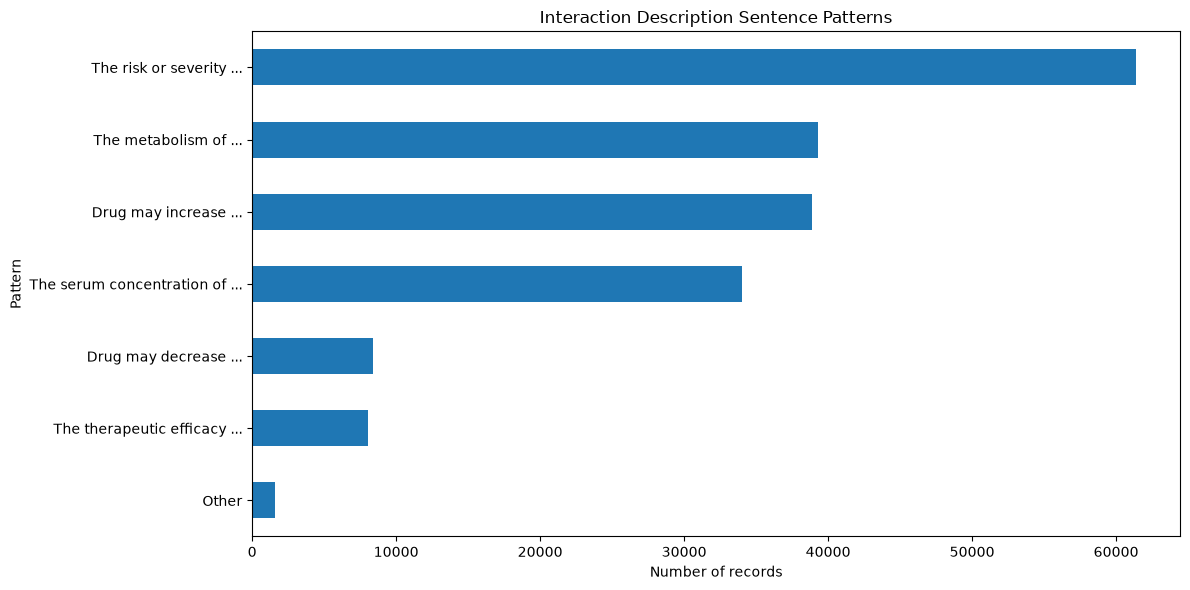

In [27]:
# Normalize drug names in descriptions so we can inspect recurring templates approximately.
template_df = df.copy()

def normalize_description(text):
    text = text.lower()
    text = re.sub(r"\b[A-Za-z][A-Za-z0-9-]*(?: [A-Za-z][A-Za-z0-9-]*){0,3}\b", "<TERM>", text)
    return text

# A lighter approach: classify by common sentence starts.
def sentence_pattern(text):
    t = text.lower()
    if t.startswith("the metabolism of"):
        return "The metabolism of ..."
    if t.startswith("the serum concentration of"):
        return "The serum concentration of ..."
    if t.startswith("the risk or severity"):
        return "The risk or severity ..."
    if t.startswith("the therapeutic efficacy"):
        return "The therapeutic efficacy ..."
    if " may increase " in t:
        return "Drug may increase ..."
    if " may decrease " in t:
        return "Drug may decrease ..."
    return "Other"

template_counts = df["Interaction Description"].map(sentence_pattern).value_counts()
display(template_counts.to_frame("records"))

plt.figure(figsize=(12, 6))
template_counts.sort_values().plot(kind="barh")
plt.title("Interaction Description Sentence Patterns")
plt.xlabel("Number of records")
plt.ylabel("Pattern")
plt.tight_layout()
plt.show()


## 15. Most common drug-pair records

In [28]:
# Directed pairs with multiple records
multi_pair = (
    df.groupby(["Drug 1", "Drug 2"])
      .agg(
          records=("Interaction Description", "size"),
          descriptions=("Interaction Description", lambda x: list(x))
      )
      .query("records > 1")
      .sort_values("records", ascending=False)
)

display(multi_pair.head(20))


records  \
Drug 1       Drug 2                      
Amodiaquine  Celecoxib               2   
             Clotrimazole            2   
             Crisaborole             2   
             Efavirenz               2   
             Felodipine              2   
             Irbesartan              2   
             Lapatinib               2   
             Losartan                2   
             Nilotinib               2   
             Pioglitazone            2   
             Quinine                 2   
             Rabeprazole             2   
             Rosiglitazone           2   
             Sulfamethoxazole        2   
             Tamoxifen               2   
             Teriflunomide           2   
             Topiroxostat            2   
Amphetamine  Bupropion               2   
Azithromycin Mifepristone            2   
Bedaquiline  Mifepristone            2   

                                                                                                                                          descriptions  
Drug 1       Drug 2                                                                                                                                     
Amodiaquine  Celecoxib         [The metabolism of Celecoxib can be decreased when combined with Amodiaquine., The serum concentration of Celecoxib ...  
             Clotrimazole      [The metabolism of Clotrimazole can be decreased when combined with Amodiaquine., The serum concentration of Clotrim...  
             Crisaborole       [The metabolism of Crisaborole can be decreased when combined with Amodiaquine., The serum concentration of Crisabor...  
             Efavirenz         [The serum concentration of Efavirenz can be increased when it is combined with Amodiaquine., Amodiaquine may increa...  
             Felodipine        [The metabolism of Felodipine can be decreased when combined with Amodiaquine., The serum concentration of Felodipin...  
             Irbesartan        [The metabolism of Irbesartan can be decreased when combined with Amodiaquine., The serum concentration of Irbesarta...  
             Lapatinib         [The metabolism of Lapatinib can be decreased when combined with Amodiaquine., The serum concentration of Lapatinib ...  
             Losartan          [The metabolism of Losartan can be decreased when combined with Amodiaquine., The serum concentration of Losartan ca...  
             Nilotinib         [The metabolism of Nilotinib can be decreased when combined with Amodiaquine., The serum concentration of Nilotinib ...  
             Pioglitazone      [The metabolism of Pioglitazone can be decreased when combined with Amodiaquine., The serum concentration of Pioglit...  
             Quinine           [The metabolism of Quinine can be decreased when combined with Amodiaquine., The serum concentration of Quinine can ...  
             Rabeprazole       [The metabolism of Rabeprazole can be decreased when combined with Amodiaquine., The serum concentration of Rabepraz...  
             Rosiglitazone     [The metabolism of Rosiglitazone can be decreased when combined with Amodiaquine., The serum concentration of Rosigl...  
             Sulfamethoxazole  [The metabolism of Sulfamethoxazole can be decreased when combined with Amodiaquine., The serum concentration of Sul...  
             Tamoxifen         [The metabolism of Tamoxifen can be decreased when combined with Amodiaquine., The serum concentration of Tamoxifen ...  
             Teriflunomide     [The metabolism of Teriflunomide can be decreased when combined with Amodiaquine., The serum concentration of Terifl...  
             Topiroxostat      [The metabolism of Topiroxostat can be decreased when combined with Amodiaquine., The serum concentration of Topirox...  
Amphetamine  Bupropion         [The metabolism of Bupropion can be decreased when combined with Amphetamine., The risk or severity of adverse effec...  
Azithromycin Mifepristone      [Azithromycin m

## 16. Optional: interaction network degree
This treats each unique unordered drug pair as an edge in a graph. Degree = number of unique drugs connected to a drug.

,unique_partner_count
Drug,
Phenobarbital,912
Phenytoin,888
Primidone,888
Fosphenytoin,870
Venlafaxine,858
Carbamazepine,855
Fluvoxamine,843
Amiodarone,839
Pentobarbital,837


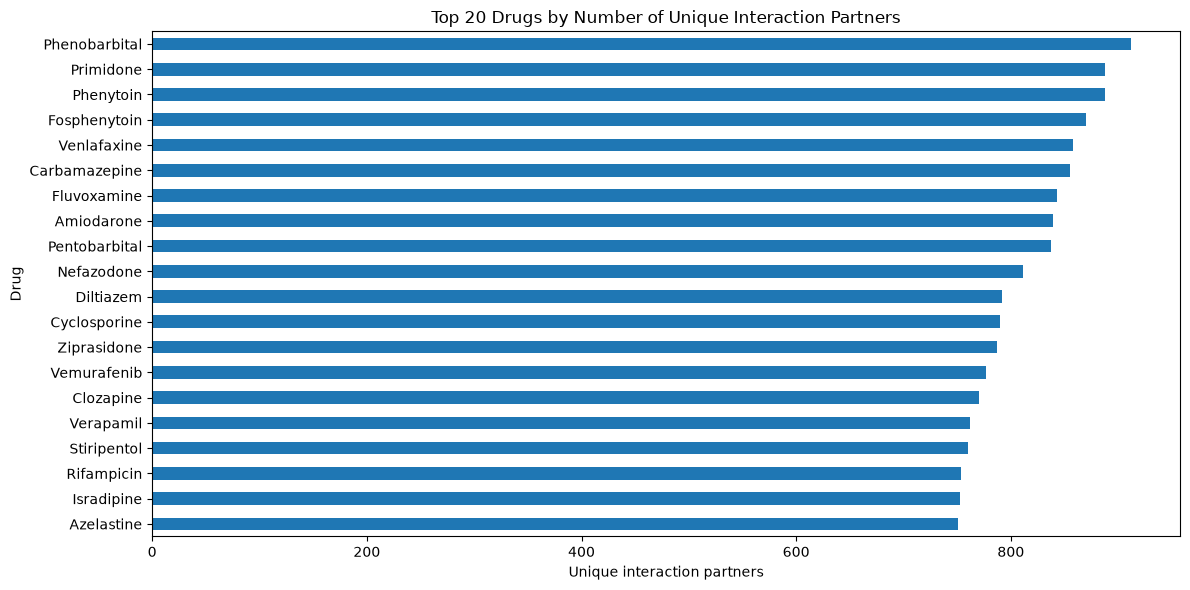

In [29]:
edges = canonical.drop_duplicates()

degree = pd.concat([
    edges["Drug_A"].rename("Drug"),
    edges["Drug_B"].rename("Drug")
]).value_counts()

display(degree.head(20).to_frame("unique_partner_count"))

plt.figure(figsize=(12, 6))
degree.head(20).sort_values().plot(kind="barh")
plt.title("Top 20 Drugs by Number of Unique Interaction Partners")
plt.xlabel("Unique interaction partners")
plt.ylabel("Drug")
plt.tight_layout()
plt.show()


## 17. EDA conclusions and ML implications

### What to record in the project report
- Dataset dimensions and column meanings.
- Missing-value status.
- Exact-row duplicate status.
- Drug-pair duplicate status.
- Reversed-pair status.
- Number of unique drugs.
- Number of unique interaction pairs.
- Distribution of interaction-description lengths.
- Main linguistic patterns in descriptions.
- Any suspicious or ambiguous records.

### Important ML considerations
1. **There is no explicit negative class.** The dataset lists interaction records; absence of a pair is not automatically proof of `no interaction`.
2. **Pair duplication needs a policy.** The same directed pair can have multiple descriptions because one drug pair may have multiple interaction mechanisms/effects.
3. **Reversed pairs need a domain decision.** If `(A, B)` and `(B, A)` are equivalent for your ML task, canonicalize the pair before splitting/training to avoid leakage.
4. **Do not randomly split duplicated/canonicalized pairs before resolving pair relationships.** Otherwise related records can appear in both train and test sets.
5. **Text descriptions can be used for NLP features, but medical severity should not be inferred from simple keywords alone.**
6. **For DDI classification, define the target carefully** (for example: interaction exists / no interaction, or a validated severity label) and obtain reliable negative examples and/or validated severity labels.


## 18. Export cleaned analysis tables (optional)

In [30]:
# Optional exports for use in reports
drug_frequency.to_csv("drug_frequency.csv", header=["appearances"])
keyword_counts.to_csv("description_keyword_counts.csv", header=["records"])
unordered_counts.to_csv("unordered_pair_counts.csv", header=["records"])

print("Exported analysis tables.")


Exported analysis tables.
